# Amenaza sísmica y refuerzo del Hospital de Golfito
Jeremy Fabrizio Fonseca Araya · C23005 · C-03.

Datos simulados del docente. Primera implementación con asistencia de ChatGPT/Codex, para revisión individual.

## Pregunta de decisión
¿Conviene reforzar el pabellón, con cuál opción y cuánta pérdida anual se evita por colón invertido? El criterio es el mayor VPN entre no invertir, A y B. Los costos, daños y horizonte se leen del Excel.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display

from src.analisis import analizar, tabla_visible
from src.graficas import (
    figura_arias,
    figura_descuento,
    figura_exploracion,
    figura_movimiento,
    figura_pae,
    figura_recurrencia,
    figura_sensibilidad,
)
from src.limpieza import leer_base

base = leer_base()
resultado = analizar(base)
display(tabla_visible(resultado["escenarios"]))

,Alternativa,Inversión,Pérdida anual,Ahorro anual,VPN,Obra (meses)
0,Sin refuerzo,₡0,₡7.785.248,₡0,₡0,0.0
1,Opción A,₡63.000.000,₡1.906.187,₡5.879.060,₡21.668.617,3.0
2,Opción B,₡164.000.000,₡602.391,₡7.182.857,-₡60.554.463,6.0


## Exploración y tratamiento
La ventana es 1996–2025: se supone completa durante 30 años. Se interpolan solo huecos internos de aceleración. La profundidad faltante se conserva porque no participa en los cálculos. IQR identifica candidatos atípicos, no errores demostrados. Se conservan los sismos grandes y los picos del acelerograma.

Catalogo_sismos (625, 5)
Acelerograma (751, 2)
Evento (1, 6)
Vulnerabilidad (13, 4)
Edificacion (4, 3)
Opciones_refuerzo (2, 4)
Diccionario (24, 4)


,hoja,variable,tipo,cantidad,criterio
0,Catalogo_sismos,profundidad_km,Faltantes,6,Se conservan vacíos; no intervienen en b ni la...
1,Acelerograma,aceleracion_cm_s2,Faltantes,3,Interpolación lineal interna
2,Catalogo_sismos,magnitud_Mw,Señal IQR,23,Conservar: cola sísmica plausible; señal estad...
3,Catalogo_sismos,profundidad_km,Señal IQR,18,Conservar: cola sísmica plausible; señal estad...
4,Catalogo_sismos,distancia_sitio_km,Señal IQR,0,Conservar: cola sísmica plausible; señal estad...
5,Acelerograma,aceleracion_cm_s2,Picos,0,No se recortan picos: representan el movimient...


,id_sismo,fecha_hora,magnitud_Mw,profundidad_km,distancia_sitio_km
count,625.000000,625,625.000000,619.000000,625.000000
mean,313.000000,2011-06-03 10:11:30.750400,3.336160,22.116155,84.824480
min,1.000000,1996-02-07 12:47:24,3.000000,2.000000,5.800000
25%,157.000000,2003-11-29 08:39:12,3.100000,10.800000,45.700000
50%,313.000000,2011-08-18 20:29:30,3.200000,19.000000,83.600000
75%,469.000000,2018-05-11 05:30:19,3.500000,29.600000,124.300000
max,625.000000,2025-12-30 17:45:37,6.000000,106.800000,160.000000
std,180.566239,NaN,0.370167,15.281252,44.859091


,magnitud_Mw,profundidad_km,distancia_sitio_km
magnitud_Mw,1.000000,-0.020427,-0.031987
profundidad_km,-0.020427,1.000000,-0.030482
distancia_sitio_km,-0.031987,-0.030482,1.000000


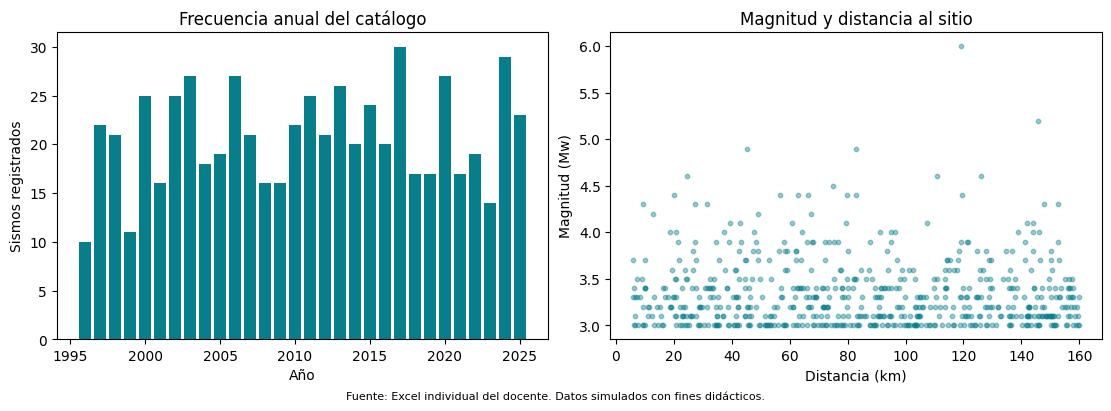

In [2]:
for nombre, tabla in base.hojas.items():
    print(nombre, tabla.shape)
display(base.incidencias)
display(base.hojas["Catalogo_sismos"].describe())
display(
    base.hojas["Catalogo_sismos"][["magnitud_Mw", "profundidad_km", "distancia_sitio_km"]].corr()
)
display(figura_exploracion(base))
plt.close("all")

## Magnitudes: de la densidad a b
Sea $\beta=b\ln(10)$ y $m_c=2.95$. $f(m)=\beta e^{-\beta(m-m_c)}$. Por sustitución y partes: $E[M]=m_c+\int_0^\infty u\beta e^{-\beta u}du=m_c+1/\beta$. Igualando a la media muestral, $b=\log_{10}(e)/(\bar m-2.95)$. La corrección de 0,05 procede del redondeo a 0,1 indicado por el enunciado.

b: 1.1246490623142
lambda3, eventos/año: 20.833333333333332
P(M>=6), 50 años: 0.3561782331254896
P(M>=7), 50 años: 0.03250694879038323


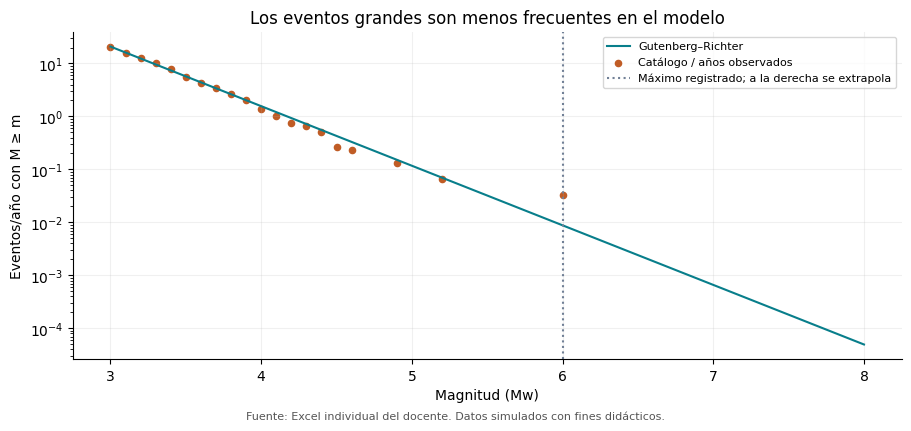

In [3]:
print("b:", resultado["b"])
print("lambda3, eventos/año:", resultado["lambda3"])
print("P(M>=6), 50 años:", resultado["prob6_50"])
print("P(M>=7), 50 años:", resultado["prob7_50"])
display(figura_recurrencia(base, resultado))
plt.close("all")

## Movimiento del suelo
$v(t)=\int_0^t a(u)du$, $x(t)=\int_0^t v(u)du$, con condiciones iniciales cero. Se resta la media previa al evento. Un sesgo constante c añade ct a v y $ct^2/2$ a x. La regla del trapecio se implementa en `src/numericos.py`.

{'linea_base_cm_s2': 1.530928,
 'PGA_cm_s2': 186.018928,
 'PGV_cm_s': 13.023220639999934,
 'PGD_cm': 8.858054400002779,
 'IA_m_s': 0.40693711555626577,
 't5_s': 7.972231077170089,
 't95_s': 18.563704344519145,
 'duracion_s': 10.591473267349055,
 'desplazamiento_final_cm': 8.858054400002779,
 'desplazamiento_final_sin_corregir_cm': 697.7756544000036}

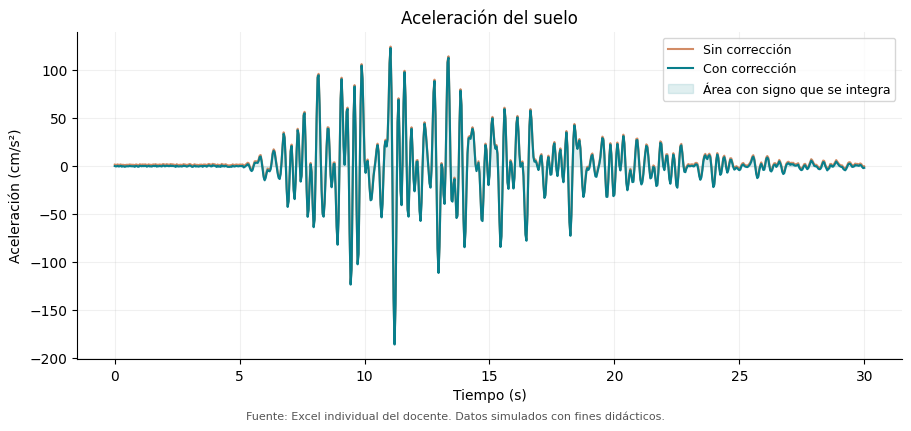

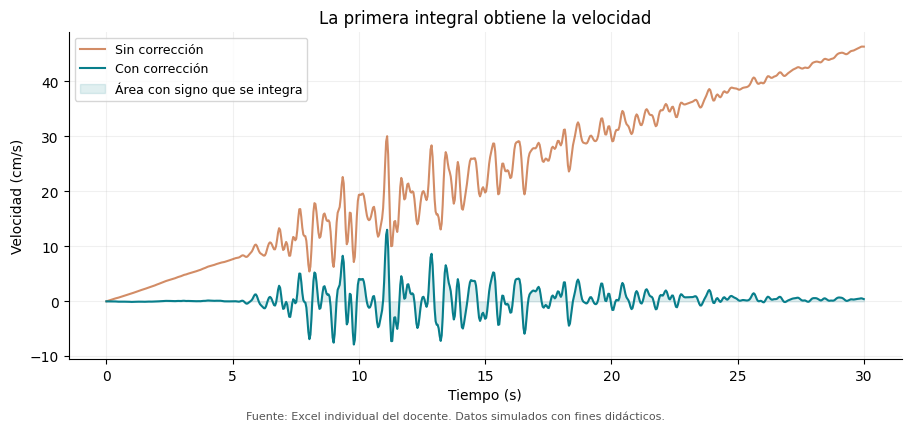

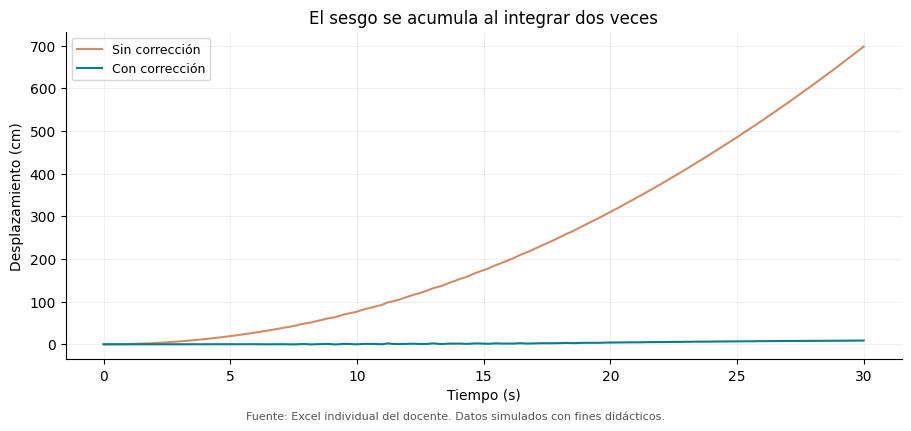

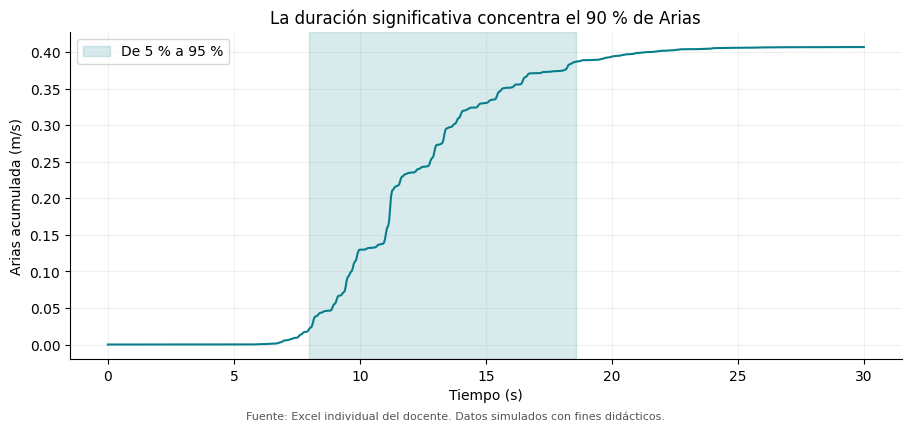

In [4]:
display(resultado["indicadores"])
for variable in ["aceleracion", "velocidad", "desplazamiento"]:
    display(figura_movimiento(resultado, variable))
    plt.close("all")
display(figura_arias(resultado))
plt.close("all")

## Daño, pérdidas y valor presente
Se interpola D linealmente entre datos, expresados como fracción. $PAE=V\int_5^8D(m)[-\lambda'(m)]dm$ en colones/año. Simpson propio usa 16 subdivisiones por tramo; se compara con la integral exacta del mismo modelo. $VPN=-C+\Delta PAE(1-e^{-rH})/r$. Para r=0 se usa $-C+\Delta PAE H$.

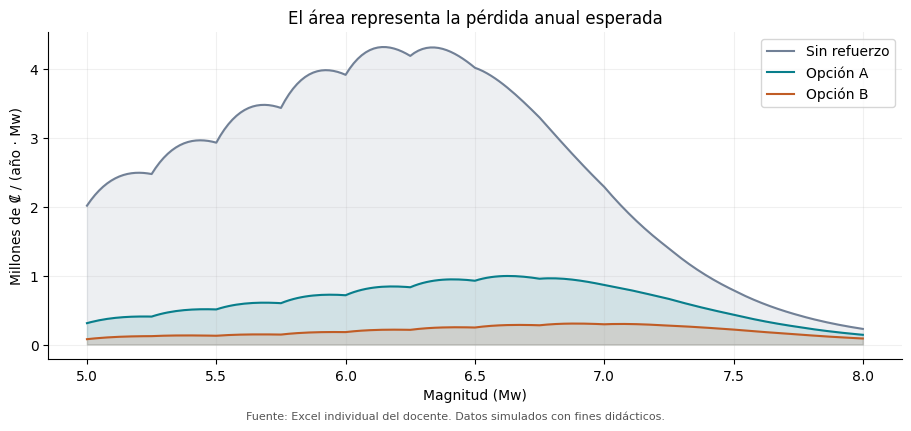

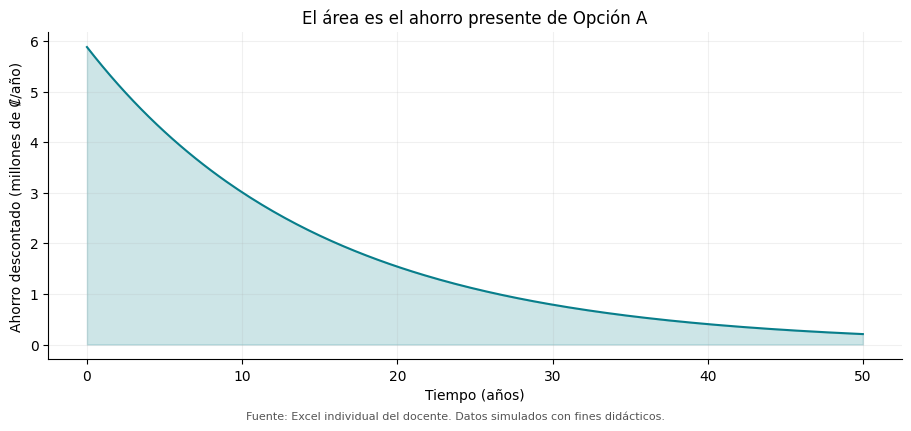

,Alternativa,Inversión,Pérdida anual,Ahorro anual,VPN,Obra (meses)
0,Sin refuerzo,₡0,₡7.785.248,₡0,₡0,0.0
1,Opción A,₡63.000.000,₡1.906.187,₡5.879.060,₡21.668.617,3.0
2,Opción B,₡164.000.000,₡602.391,₡7.182.857,-₡60.554.463,6.0


In [5]:
display(figura_pae(base, resultado))
plt.close("all")
display(figura_descuento(resultado))
plt.close("all")
display(tabla_visible(resultado["escenarios"]))

## Verificación
Para sen(t), v=1−cos(t) y x=t−sen(t). Se mide error de norma máxima, evitando cocientes en ceros. En el registro entregado, trapecio frente a Simpson mide discrepancia, no error físico. Una velocidad final cercana a cero amplifica el porcentaje.

In [6]:
display(resultado["seno"])
assert (resultado["seno"].error_relativo_max_pct < 0.5).all()
display(resultado["verificacion"])

,variable,error_relativo_max_pct,limite_pct
0,velocidad,0.000833,0.5
1,desplazamiento,0.000876,0.5


,integral,metodo,valor,referencia,valor_referencia,unidad,error_relativo_pct,diferencia_absoluta
0,Integral a(t),Trapecio,4.106000e-01,Simpson,4.660533e-01,cm/s,1.189850e+01,0.055453
1,Integral v(t),Trapecio,8.858054e+00,Simpson,8.858299e+00,cm,2.763510e-03,0.000245
2,Arias,Trapecio,4.069371e-01,Simpson,4.068620e-01,m/s,1.846671e-02,0.000075
3,PAE dano_actual_pct,Simpson refinado,7.785248e+06,Exacta D lineal,7.785248e+06,colones/año,3.937844e-06,0.306571
4,PAE dano_actual_pct,Trapecio refinado,7.784374e+06,Exacta D lineal,7.785248e+06,colones/año,1.122231e-02,873.684399
5,PAE dano_actual_pct,Simpson tabla original,7.579540e+06,Exacta D lineal,7.785248e+06,colones/año,2.642277e+00,205707.789884
6,PAE dano_opcion_A_pct,Simpson refinado,1.906187e+06,Exacta D lineal,1.906187e+06,colones/año,4.262201e-06,0.081246
7,PAE dano_opcion_A_pct,Trapecio refinado,1.905945e+06,Exacta D lineal,1.906187e+06,colones/año,1.270852e-02,242.248202
8,PAE dano_opcion_A_pct,Simpson tabla original,1.848327e+06,Exacta D lineal,1.906187e+06,colones/año,3.035372e+00,57859.876486
9,PAE dano_opcion_B_pct,Simpson refinado,6.023907e+05,Exacta D lineal,6.023907e+05,colones/año,4.504057e-06,0.027132


## Sensibilidad y condiciones de la decisión
Se prueba b±0,1 del enunciado y descuento ±2 puntos porcentuales como supuesto de sensibilidad. La recomendación puede cambiar. Los escenarios no son un intervalo de confianza estadístico.

Recomendación base: {'escenario': 'Opción A', 'costo_colones': 63000000.0, 'pae_colones_ano': 1906187.189224309, 'ahorro_anual_colones': 5879060.405689008, 'vpn_colones': 21668617.442321733, 'plazo_meses': 3.0, 'ahorro_anual_por_colon': 0.09331841913792076, 'descripcion': 'Encamisado de columnas y vigas'}


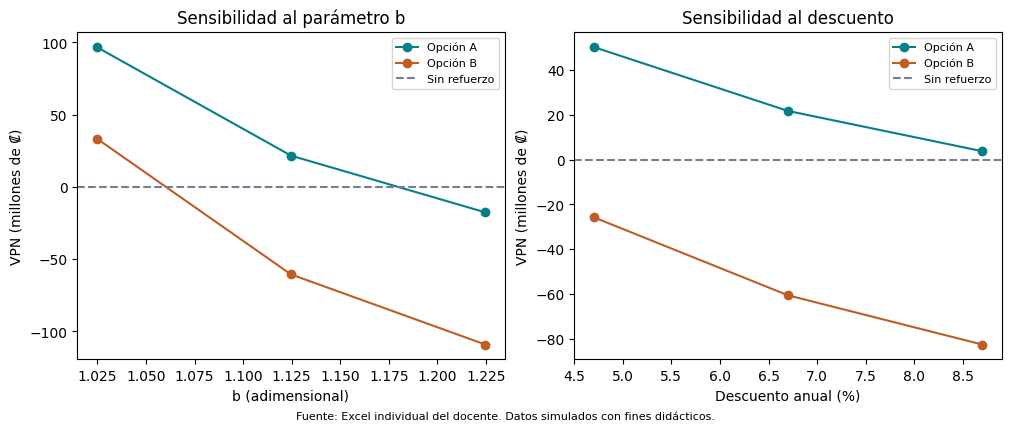

,b,r_pct,delta_b,delta_r_pp,escenario,vpn_colones,recomendacion
0,1.024649,4.7,-0.1,-2.0,Sin refuerzo,0.000000e+00,Opción A
1,1.024649,4.7,-0.1,-2.0,Opción A,1.506307e+08,Opción A
2,1.024649,4.7,-0.1,-2.0,Opción B,9.999054e+07,Opción A
3,1.024649,6.7,-0.1,0.0,Sin refuerzo,0.000000e+00,Opción A
4,1.024649,6.7,-0.1,0.0,Opción A,9.684706e+07,Opción A
5,1.024649,6.7,-0.1,0.0,Opción B,3.352832e+07,Opción A
6,1.024649,8.7,-0.1,2.0,Sin refuerzo,0.000000e+00,Opción A
7,1.024649,8.7,-0.1,2.0,Opción A,6.292995e+07,Opción A
8,1.024649,8.7,-0.1,2.0,Opción B,-8.384183e+06,Opción A
9,1.124649,4.7,0.0,-2.0,Sin refuerzo,0.000000e+00,Opción A


In [7]:
display(figura_sensibilidad(resultado))
plt.close("all")
display(resultado["sensibilidad"])
print("Recomendación base:", resultado["recomendacion"])

## Límites y referencias
Los datos son simulados. La ley regional se extrapola más allá del máximo registrado. No se incluye atenuación, respuesta estructural, lesiones o interrupción hospitalaria. El registro aislado y las curvas de daño no constituyen una evaluación estructural.

Ver `docs/MATEMATICA.md`, `docs/BITACORA.md` y `docs/REFERENCIAS.md` para las deducciones completas, los supuestos y las fuentes.